# NumPy Indexing, Slicing, and Fancy Indexing

Analysis is mostly **selection**: the hot days, the last week, the rows where a sensor failed. NumPy offers four ways to select elements, and the difference between a **view** and a **copy** decides whether a change affects the original data.

**After this lesson you can:**

1. Select single elements and slices in 1-D and 2-D arrays.
2. Explain views vs copies and avoid accidental changes.
3. Filter with boolean masks and combine conditions.
4. Select arbitrary positions with integer arrays (fancy indexing), and find top-*k* values.

**Data:** Seattle daily weather, 2012–2015, as a (years × days) matrix.

In [1]:
import sys
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

sys.path.insert(0, str(Path.cwd().parent / "tools"))
import datasets                                   # course helper: downloads pinned public datasets

weather = pd.read_csv(datasets.fetch("seattle-weather.csv"), parse_dates=["date"])   # NOAA daily weather, Seattle

w = weather[~((weather["date"].dt.month == 2) & (weather["date"].dt.day == 29))]     # drop 29 February -> 365 days per year
# pandas 3 (Copy-on-Write) returns READ-ONLY arrays from to_numpy(); copy() gives a writable array of our own
temp = w["temp_max"].to_numpy().copy().reshape(4, 365)   # row = year (2012..2015), column = day of year
rain = w["precipitation"].to_numpy().copy().reshape(4, 365)
print("writable without copy():", w["temp_max"].to_numpy().flags.writeable, "| with copy():", temp.flags.writeable)
years = np.array([2012, 2013, 2014, 2015])
print(temp.shape)

writable without copy(): False | with copy(): True
(4, 365)


## 1. Basic Indexing and Slicing

- Indexes start at 0; negative indexes count from the end.
- A slice `start:stop:step` excludes `stop`.
- In 2-D, `a[row, column]`; `a[1]` is the second row, `a[:, 0]` the first column.

In [2]:
print("1 Jan 2012          :", temp[0, 0])
print("31 Dec 2015         :", temp[-1, -1])
print("first week of 2013  :", temp[1, :7])
print("every 30th day, 2014:", temp[2, ::30])
print("1 July of all years :", temp[:, 181])
print("summer 2015 shape   :", temp[3, 152:244].shape, "(June to August)")

1 Jan 2012          : 12.8
31 Dec 2015         : 5.6
first week of 2013  : [ 5.   6.1  6.7 10.   6.7  7.2 10. ]
every 30th day, 2014: [ 7.2  7.8 11.1 14.4 29.4 23.3 25.6 29.4 22.8 18.9 15.  14.4  9.4]
1 July of all years : [20.  31.7 34.4 32.2]
summer 2015 shape   : (92,) (June to August)


## 2. Views and Copies

A **slice** returns a **view**: a new array object that points to the **same memory**. Changing the view changes the original. Use `.copy()` when you need independent data. `np.shares_memory(a, b)` tells you which case you have.

In [3]:
first_week = temp[0, :7]                        # a view
backup = temp[0, :7].copy()                     # a copy
print("view shares memory:", np.shares_memory(first_week, temp), "| copy shares memory:", np.shares_memory(backup, temp))

first_week[0] = 99.0                            # change through the view ...
print("original temp[0, 0] is now:", temp[0, 0], "<- changed")
temp[0, 0] = backup[0]                          # restore it
print("restored:", temp[0, 0])

view shares memory: True | copy shares memory: False
original temp[0, 0] is now: 99.0 <- changed
restored: 12.8


## 3. Boolean Masks

A comparison returns a **boolean array** of the same shape. Use it as an index to keep the `True` positions. Combine conditions with `&` (and), `|` (or), `~` (not), and put each condition in parentheses.

In [4]:
hot = temp >= 30
print("hot days (>= 30 °C) per year:", dict(zip(years.tolist(), hot.sum(axis=1).tolist())))
print("temperatures of the hot days in 2015:", temp[3][hot[3]])

dry_warm = (temp >= 25) & (rain == 0)
wet_cold = (temp < 5) | (rain > 30)
print(f"dry and warm days: {dry_warm.sum()} | cold or very wet days: {wet_cold.sum()} | other days: {(~(dry_warm | wet_cold)).sum()}")

clipped = np.where(temp > 30, 30, temp)          # np.where(condition, if_true, if_false)
print("maximum after clipping:", clipped.max())

hot days (>= 30 °C) per year: {2012: 8, 2013: 15, 2014: 17, 2015: 23}
temperatures of the hot days in 2015: [31.1 30.6 30.  30.6 31.7 33.3 30.6 32.2 33.9 33.3 33.3 32.8 30.  33.3
 35.  32.2 34.4 34.4 33.3 30.6 30.  30.  31.7]
dry and warm days: 227 | cold or very wet days: 60 | other days: 1173
maximum after clipping: 30.0


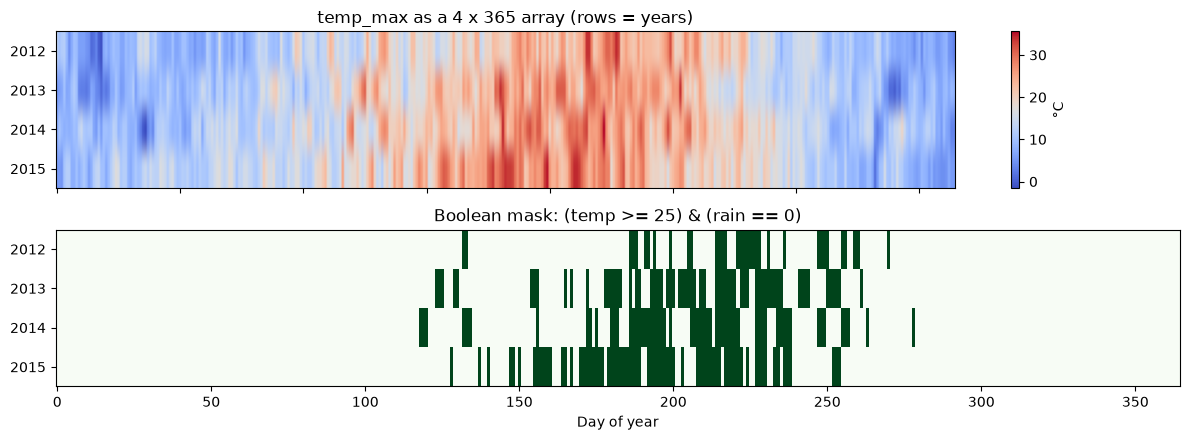

In [5]:
fig, axes = plt.subplots(2, 1, figsize=(12, 4.5), sharex=True)
im = axes[0].imshow(temp, aspect="auto", cmap="coolwarm")
axes[0].set(yticks=range(4), yticklabels=years, title="temp_max as a 4 x 365 array (rows = years)")
fig.colorbar(im, ax=axes[0], label="°C")
axes[1].imshow(dry_warm, aspect="auto", cmap="Greens")
axes[1].set(yticks=range(4), yticklabels=years, title="Boolean mask: (temp >= 25) & (rain == 0)", xlabel="Day of year")
plt.tight_layout()
plt.show()

## 4. Fancy Indexing and Top-*k*

**Fancy indexing** uses an array of integer positions. It always returns a **copy**. Combined with `argsort` (positions that would sort the array) or `argpartition` (faster for top-*k*), it answers "which days were the hottest?".

In [6]:
flat = temp.ravel()
dates = w["date"].to_numpy()
top5 = np.argsort(flat)[-5:][::-1]                # positions of the 5 largest values
print("5 hottest days:")
for i in top5:
    print(f"  {str(dates[i])[:10]}  {flat[i]} °C")

k = 10
fast_top = np.argpartition(flat, -k)[-k:]         # the k largest, in no particular order
print(f"\nargpartition finds the same top-{k} set:", set(fast_top) == set(np.argsort(flat)[-k:]))

picked = temp[[0, 3], :][:, [0, 181, 364]]       # rows 2012 and 2015, columns 1 Jan, 1 Jul, 31 Dec
print("\nfancy selection (years 2012 and 2015 x three days):\n", picked)

5 hottest days:
  2014-08-11  35.6 °C
  2015-07-19  35.0 °C
  2014-07-01  34.4 °C
  2012-08-16  34.4 °C
  2015-07-30  34.4 °C

argpartition finds the same top-10 set: True

fancy selection (years 2012 and 2015 x three days):
 [[12.8 20.   3.3]
 [ 5.6 32.2  5.6]]


| Selection | Example | Returns |
| :--- | :--- | :--- |
| basic index | `a[2, 5]` | a scalar |
| slice | `a[0, :7]` | a **view** |
| boolean mask | `a[a > 30]` | a 1-D **copy** |
| fancy (integer arrays) | `a[[0, 3]]` | a **copy** |

*Insight: Slices are views (fast, no copy, but changes propagate); masks and fancy indexing return copies. When you modify a selection, decide which one you need, and call `.copy()` when in doubt.*

## Real-World Use Case or Analogy

A view is like a **window** onto a garden: if somebody plants a tree in the garden, you see it through every window. A copy is a **photograph** of the garden: it does not change when the garden does.

Masks select the pixels of an object in an image, the anomalies in a sensor stream, or the valid rows of a dataset. Top-*k* selection with `argpartition` is how recommender systems and vector search (M07, M28) return the *k* best items quickly.